# 05 · The AI model: hidden tastes (T9)

**Step T9 of the project plan.** This is the clearly-AI part of the project. The model looks only at who joined which groups and learns, by itself,
a short list of *hidden tastes*: patterns such as "people who join exam groups also join other exam groups". Nobody tells it the topics.
A user's score for a group is how well the group fits the tastes of the user's groups. This family of methods (matrix factorisation) won the Netflix Prize.

What this notebook does:

1. learns the tastes with an exact method that BOING's JavaScript can redo, and checks that it gives the same scores as scikit-learn's `TruncatedSVD`;
2. chooses the number of tastes on the practice quiz, then scores the model on the test, like the other methods (notebook 04);
3. the **nice check**: do the tastes match the real topics, which the model never saw? If they do, the AI found people's interests without being told:
   exactly the profiling the ethics part of the project is about;
4. shows how each suggestion gets an honest reason ("Because you're in Daily coding").

Run notebooks 01 and 02 first. The code shared by all notebooks is in `boingrec.py`, in this folder.

## 0 · Settings and data

In [1]:
# Colab only: upload sim_v1.zip and sim_v1_split.zip (from notebooks 01 and 02) and boingrec.py (from the notebooks folder),
# all three at once. Locally this cell does nothing.
import sys, zipfile
from pathlib import Path
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    for fname in files.upload():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall('data')

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import boingrec as br

SEED, K = br.SEED, br.K          # 0 and 5, the same in every notebook
K_CHOICES = [5, 10, 20, 40]      # numbers of hidden tastes to try (the plan says 5, 10 and 20; we add 40)
br.use_style()

vis = br.load_visible()          # what a recommender may read: no test file, no hidden column
ans = br.load_answers()          # the answer key: only the scoring code reads it (sections 3 to 5)
tested = sorted(ans.test.user_id.unique())
gids = br.group_ids(vis)
name = vis.groups.set_index('group_id').name
print(f'{len(vis.train)} visible memberships, {len(ans.test)} hidden ones, {len(tested)} users to test, '
      f'{len(gids)} groups ({len(br.discover_groups(vis.groups))} on Discover)')

6428 visible memberships, 1531 hidden ones, 1406 users to test, 150 groups (129 on Discover)


## 1 · How the model learns tastes

1. **X** is the users × groups table of 0s and 1s from the training data (1 = member), as in notebook 04.
2. **X<sup>T</sup>X** is a groups × groups table: how many members each pair of groups shares. On its diagonal: each group's size.
3. **The tastes** are the strongest patterns in that table (its *eigenvectors*). A taste gives every group a number, its *loading*:
   far from 0 for groups that tend to be joined together. We keep the *k* strongest; their *strength* says how much of the table each one explains.
4. **A user's scores** = the user's row of X projected on the tastes: X V V<sup>T</sup>, where the columns of V are the tastes.
   Groups that fit the tastes of the user's own groups get high scores; we keep the 5 best the user can join.

The plan names scikit-learn's `TruncatedSVD`, which finds the same tastes with an iterative method. We use `numpy.linalg.eigh` instead: it is exact,
gives the same answer every time, and is easy to port to JavaScript for BOING. Section 2 checks that both give the same scores.

Note for the privacy part: the model needs nothing about other members except X<sup>T</sup>X, a count of shared members.
That is the table rule R10 will protect with noise (experiment E3).

In [3]:
X = br.membership_matrix(vis)                   # users x groups, 0/1 (training data)
gram = X.T @ X                                  # groups x groups: members each pair of groups shares
a, b = 4, 23                                    # Finals countdown and Midterms countdown, two of user 1's groups
print(f'X: {X.shape[0]} users x {X.shape[1]} groups, {int(X.to_numpy().sum())} memberships')
print(f'X^T X for {name[a]} and {name[b]}: {gram.loc[a, b]} members in both. '
      f'For {name[a]} with itself: {gram.loc[a, a]}, its size.')

strength10, tastes10 = br.taste_model(gram.to_numpy(), k=10)
print('\nStrength of the 10 strongest tastes:', ', '.join(str(int(round(s))) for s in strength10))
print('Each group gets one loading per taste, for example:')
pd.DataFrame(tastes10, index=gids, columns=pd.Index(range(1, 11), name='taste')).loc[[4, 7, 10]].rename(index=name).round(2)

X: 2000 users x 150 groups, 6428 memberships
X^T X for Finals countdown and Midterms countdown: 113 members in both. For Finals countdown with itself: 286, its size.

Strength of the 10 strongest tastes: 622, 422, 388, 350, 284, 237, 227, 181, 177, 145
Each group gets one loading per taste, for example:


taste,1,2,3,4,5,6,7,8,9,10
Finals countdown,0.32,0.48,-0.30,-0.23,-0.11,-0.03,0.03,-0.02,0.02,0.05
Korean conversation club,0.38,-0.43,-0.17,-0.14,-0.09,-0.05,0.03,0.04,0.10,-0.60
Weightlifting for beginners,0.36,0.07,0.05,0.68,-0.09,-0.11,-0.02,-0.10,-0.02,-0.05


## 2 · The same as scikit-learn's `TruncatedSVD`

For each number of tastes we compute every tested user's scores both ways and look at the largest difference.
`TruncatedSVD(algorithm='arpack')` is fitted on the same X; its scores are `transform(X) @ components_`.
Its *singular values*, squared, should equal our strengths.

In [4]:
from sklearn.decomposition import TruncatedSVD

x_all = X.to_numpy(dtype=float)
x_tested = br.membership_matrix(vis, tested).to_numpy(dtype=float)
same_rows = {}
for k in K_CHOICES:
    ours = br.hidden_tastes_scores(vis, tested, k=k).to_numpy()
    svd = TruncatedSVD(n_components=k, algorithm='arpack', random_state=SEED).fit(x_all)
    theirs = svd.transform(x_tested) @ svd.components_
    strength_k, _ = br.taste_model(gram.to_numpy(), k)
    same_rows[f'{k} tastes'] = {
        'largest score difference': np.abs(ours - theirs).max(),
        'largest score': np.abs(ours).max(),
        'largest strength difference (relative)': np.abs(strength_k - svd.singular_values_ ** 2).max() / strength_k.max()}
same = pd.DataFrame(same_rows).T
same.map(lambda v: f'{v:.1e}')

,largest score difference,largest score,largest strength difference (relative)
5 tastes,2.4e-15,1.4e+00,8.2e-16
10 tastes,1.7e-14,1.5e+00,1.2e-15
20 tastes,2.5e-14,1.5e+00,7.8e-16
40 tastes,8.7e-15,1.4e+00,2.4e-15


The scores agree to about 10<sup>-14</sup>, the rounding error of a computer: it is the same model.

## 3 · How many tastes? The practice quiz decides

As in notebook 04, settings are chosen on a **practice quiz** carved from the training data (users with 3 or more training groups get 20% hidden),
never on the test. We try 5, 10, 20 and 40 tastes and keep the best NDCG@5.

In [5]:
fit, val = br.val_split(vis)       # fit: the training data minus the practice answers; val: the practice answers
val_users = sorted(val.user_id.unique())
val_rows = {}
for k in K_CHOICES:
    lists_k = br.top_k(br.hidden_tastes_scores(fit, val_users, k=k), fit)
    val_rows[f'{k} tastes'] = br.evaluate(lists_k, val, fit, ans.group_topic)
val_table = pd.DataFrame(val_rows).T
val_table[['users', 'coverage']] = val_table[['users', 'coverage']].astype(int)
br.save_table(val_table, 't9_validation.csv')

TASTES = K_CHOICES[int(np.argmax(val_table['ndcg@5'].to_numpy()))]    # ties: the fewer tastes
t6 = pd.read_csv(br.RESULTS / 't6_validation.csv', index_col=0)
print(f'Chosen: {TASTES} tastes (boingrec.TASTES = {br.TASTES}). On the same practice quiz, NDCG@5 of "also joined" = '
      f'{t6.loc[br.label("also_joined"), "ndcg@5"]:.3f}, popularity = {t6.loc[br.label("popularity"), "ndcg@5"]:.3f}.')
val_table[['hit_rate', 'ndcg@5', 'newcomer_share', 'gini', 'coverage']].round(3)

Chosen: 10 tastes (boingrec.TASTES = 10). On the same practice quiz, NDCG@5 of "also joined" = 0.441, popularity = 0.122.


,hit_rate,ndcg@5,newcomer_share,gini,coverage
5 tastes,0.450,0.339,0.000,0.791,47
10 tastes,0.533,0.393,0.005,0.711,66
20 tastes,0.394,0.278,0.014,0.654,79
40 tastes,0.171,0.119,0.060,0.677,90


**Ten tastes** work best. With 5, the model only knows the broadest patterns. With more, it starts to copy each user's own groups back
(with as many tastes as groups, X V V<sup>T</sup> = X exactly), and those groups can't be suggested: at 40 tastes it is no better than popularity
(NDCG@5 0.119 against 0.122).
On the practice quiz the AI model is good, but not as good as "also joined".

## 4 · The test: the AI model in the comparison table

The real quiz, once, with 10 tastes learned from all the training data. The other rows are notebook 04's table (E1, version 1).

In [6]:
strength, tastes = br.taste_model(gram.to_numpy(), TASTES)
scores = br.hidden_tastes_scores(vis, tested, k=TASTES)
test_lists = br.top_k(scores, vis)
row = br.evaluate(test_lists, ans.test, vis, ans.group_topic)
per_user = br.relevance_per_user(test_lists, ans.test)
for metric in ['hit_rate', 'ndcg@5']:
    row[f'{metric} low'], row[f'{metric} high'] = br.bootstrap_ci(per_user[metric])
row['tastes'] = TASTES
t9 = row.to_frame(br.label('hidden_tastes')).T
t9[['users', 'coverage', 'tastes']] = t9[['users', 'coverage', 'tastes']].astype(int)
br.save_table(t9, 't9_ai_model.csv')

e1_v1 = pd.read_csv(br.RESULTS / 'e1_v1.csv', index_col=0)
print(f'NDCG@5 of the AI model: {row["ndcg@5"]:.3f} (95% range {row["ndcg@5 low"]:.3f} to {row["ndcg@5 high"]:.3f})')
pd.concat([e1_v1, t9[e1_v1.columns]]).round(3)

NDCG@5 of the AI model: 0.475 (95% range 0.452 to 0.496)


,users,hit_rate,precision@5,recall@5,ndcg@5,newcomer_share,gini,coverage,largest_share,topics_per_list
Random (floor),1406,0.048,0.010,0.043,0.025,0.417,0.079,129,0.010,4.063
Popularity (today),1406,0.220,0.044,0.207,0.131,0.000,0.953,10,0.174,3.228
"""Also joined""",1406,0.640,0.136,0.621,0.499,0.027,0.599,94,0.031,2.037
Similar descriptions,1406,0.263,0.054,0.247,0.159,0.416,0.502,125,0.038,1.976
Hidden tastes (AI model),1406,0.610,0.129,0.591,0.475,0.005,0.645,76,0.037,2.251


**Who gets shown.** The AI model is far more relevant than popularity, close to "also joined", and it shows 76 different groups instead of 10.
But it gives new or small groups even fewer slots than "also joined": a group needs members before the model can learn where it fits,
and its first taste is simply group size (section 5). So it favours established groups much like "also joined" does,
though far less than popularity (Gini 0.645 against 0.953).

## 5 · The nice check: did the AI find the topics nobody told it?

Each taste has **two ends**: the groups with the highest loadings and the groups with the lowest (most negative) ones.
For each end we take its 10 groups and count their **hidden topics**, the answer key from notebook 01 (scoring code only: the model never saw them).
If one topic dominates an end, the model discovered that topic by itself. For comparison, 10 groups drawn at random share their most common topic
about 3 times in 10 (computed below).

In [7]:
topic = ans.group_topic.reindex(gids)               # scoring code only: the hidden topics
TOPICS = sorted(topic.unique())
TOP = 10
size = br.group_sizes(vis)
pole_rows = []
for t in range(TASTES):
    loading = pd.Series(tastes[:, t], index=gids)
    ends = [('+', loading)] + ([('-', -loading)] if t > 0 else [])   # taste 1 has one end: every loading is >= 0
    for end, values in ends:
        top = values.sort_values(ascending=False, kind='stable').index[:TOP]
        counts = topic[top].value_counts().sort_index().sort_values(ascending=False, kind='stable')
        pole_rows.append({'taste': t + 1, 'end': end, 'main topic': counts.index[0], 'share': counts.iloc[0] / TOP,
                          'top groups': ', '.join(name[top[:4]]), **{tp: int(counts.get(tp, 0)) for tp in TOPICS}})
poles = pd.DataFrame(pole_rows)
poles.to_csv(br.RESULTS / 't9_tastes.csv', index=False)

rng = np.random.default_rng(SEED)
joined = gids[size.to_numpy() > 0]
chance = np.mean([topic[rng.choice(joined, TOP, replace=False)].value_counts().iloc[0] / TOP for _ in range(2000)])
best_per_topic = poles[TOPICS].max().sort_values(ascending=False)
size_corr = np.corrcoef(tastes[:, 0], size.to_numpy())[0, 1]
print(f'Taste 1 follows group size: correlation {size_corr:.2f} between its loadings and the groups\' sizes.')
print(f'Chance: 10 random groups share their most common topic {chance * TOP:.1f} times in 10 on average.')
print('Best end for each hidden topic (groups of 10 in that topic):',
      ', '.join(f'{tp} {n}' for tp, n in best_per_topic.items()))
poles[['taste', 'end', 'main topic', 'share', 'top groups']]

Taste 1 follows group size: correlation 0.96 between its loadings and the groups' sizes.
Chance: 10 random groups share their most common topic 2.9 times in 10 on average.
Best end for each hidden topic (groups of 10 in that topic): languages 10, fitness 9, music 8, coding 8, art 7, careers 6, habits 6, exam_prep 6, maths 6, physics 3


,taste,end,main topic,share,top groups
0,1,+,coding,0.3,"Korean conversation club, Weightlifting for be..."
1,2,+,exam_prep,0.6,"Finals countdown, Midterms countdown, SAT prep..."
2,2,-,languages,1.0,"Korean conversation club, Japanese in 90 days,..."
3,3,+,coding,0.8,"Algorithms study group, Algorithms from zero, ..."
4,3,-,exam_prep,0.5,"Finals countdown, Midterms countdown, Korean c..."
5,4,+,fitness,0.9,"Weightlifting for beginners, 30 days of Cyclin..."
6,4,-,coding,0.4,"Finals countdown, Algorithms from zero, Algori..."
7,5,+,maths,0.6,"Mastering Probability, Calculus help desk, Geo..."
8,5,-,coding,0.4,"Algorithms study group, Finals countdown, Dail..."
9,6,+,art,0.5,"Guitar club, 3D modelling club, Drums practice..."


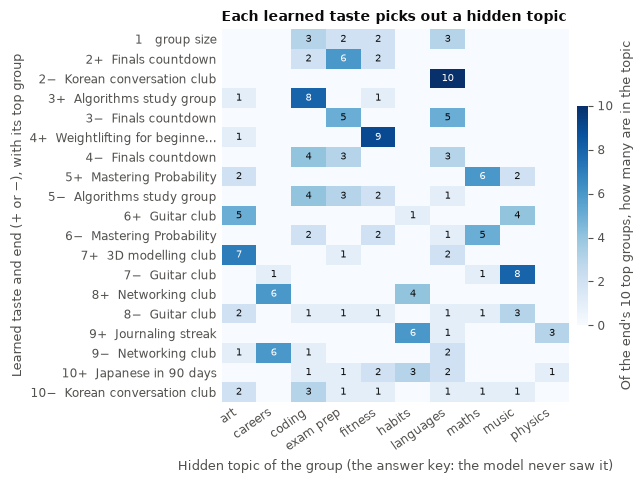

In [8]:
def short(text, n=26):
    return text if len(text) <= n else text[:n - 1] + '…'

heat = poles[TOPICS].to_numpy()
row_labels = ['1   group size' if r.taste == 1 else
              f'{r.taste}{"+" if r.end == "+" else "−"}  {short(r["top groups"].split(", ")[0])}' for _, r in poles.iterrows()]
fig, ax = plt.subplots(figsize=(br.WIDTH, 4.9))
im = ax.imshow(heat, cmap='Blues', vmin=0, vmax=TOP, aspect='auto')
for (r, c), v in np.ndenumerate(heat):
    if v > 0:
        ax.text(c, r, v, ha='center', va='center', fontsize=7.5, color='white' if v >= 6 else br.INK)
ax.set_xticks(range(len(TOPICS)), [tp.replace('_', ' ') for tp in TOPICS], rotation=35, ha='right')
ax.set_yticks(range(len(row_labels)), row_labels)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xlabel('Hidden topic of the group (the answer key: the model never saw it)')
ax.set_ylabel('Learned taste and end (+ or −), with its top group')
ax.set_title('Each learned taste picks out a hidden topic')
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label('Of the end\'s 10 top groups, how many are in the topic')
cbar.outline.set_visible(False)
fig.tight_layout()
br.save_fig(fig, 't9_tastes.png')
plt.show()

**Yes, it found them.** Taste 1 is group size. Most other ends are dominated by one hidden topic, far above chance:
one end of taste 2 is 10 language groups out of 10, and fitness, coding, music and art each fill 7 to 9 of the 10 groups at some end.
The model was never told any topic: it inferred them from who joins what. That is the profiling the ethics part is about.
It is accurate, but it learns things about members they never said, so rules R1 (opt-in) and R10 (noise on the counts) apply to it.
Physics is the topic it finds least, probably because its groups are few and small, so they leave little trace in X<sup>T</sup>X.

## 6 · Why this suggestion? An honest reason

A user's score for group *g* is a sum over the user's own groups *j* of (V V<sup>T</sup>)[*j*, *g*]: how strongly the model links *j* to *g*.
So the score splits exactly into one contribution per group the user is in, and the largest one is a true reason:
"Because you're in *j*". Here is user 1's first suggestion.

In [9]:
links = br.taste_links(tastes, gids)                   # V V^T: groups x groups
u = 1
mine = sorted(vis.train.group_id[vis.train.user_id == u])
g = test_lists[u][0]
adds = links.loc[mine, g]
print(f'User {u}\'s first suggestion: {name[g]}, score {scores.loc[u, g]:.4f}')
print(f'Sum of the contributions below: {adds.sum():.4f}')
print(f'Reason shown: "Because you\'re in {name[adds.idxmax()]}"\n')
adds.rename(index=name).sort_values(ascending=False).round(4).to_frame('adds to the score')

User 1's first suggestion: SAT prep squad, score 0.4284
Sum of the contributions below: 0.4284
Reason shown: "Because you're in Finals countdown"



,adds to the score
group_id,
Finals countdown,0.2681
Midterms countdown,0.2007
Journaling streak,-0.0098
Korean conversation club,-0.0306


## 7 · Checks

In [10]:
all_strengths = np.sort(np.linalg.eigvalsh(gram.to_numpy(dtype=float)))[::-1]
allowed = br.candidate_mask(vis, tested)
again = br.top_k(br.hidden_tastes_scores(vis, tested, k=TASTES), vis)
pairs = lambda df: set(zip(df.user_id, df.group_id))

checks = {
    'our scores equal scikit-learn TruncatedSVD (arpack) for every k (difference below 1e-9)':
        bool((same['largest score difference'] < 1e-9).all()),
    'our strengths equal TruncatedSVD\'s singular values squared': bool((same['largest strength difference (relative)'] < 1e-9).all()),
    'the tastes are orthonormal (length 1, at right angles to each other)': np.allclose(tastes.T @ tastes, np.eye(TASTES)),
    'the tastes are well defined: the 10th and 11th strengths differ':
        all_strengths[TASTES - 1] - all_strengths[TASTES] > 1e-6 * all_strengths[0],
    'every score is exactly the sum of its contributions (the reasons add up)':
        np.allclose(x_tested @ links.to_numpy(), scores.to_numpy()),
    'every tested user gets 5 different groups, all allowed (on Discover, not joined, not "not interested")':
        all(len(set(test_lists[u])) == K and all(allowed.loc[u, g] for g in test_lists[u]) for u in tested),
    'boingrec.TASTES is the number chosen on the practice quiz': TASTES == br.TASTES,
    'same seed, same results: running it again gives the same lists': again == test_lists,
    'a recommender never gets a hidden column or a test membership':
        not {'interests', 'is_fake'} & set(vis.users.columns) and 'topic' not in vis.groups.columns
        and not pairs(vis.train) & pairs(ans.test),
}
for check, ok in checks.items():
    print('✓' if ok else '✗', check)
assert all(checks.values()), 'Some checks failed (see ✗ above)'

✓ our scores equal scikit-learn TruncatedSVD (arpack) for every k (difference below 1e-9)
✓ our strengths equal TruncatedSVD's singular values squared
✓ the tastes are orthonormal (length 1, at right angles to each other)
✓ the tastes are well defined: the 10th and 11th strengths differ
✓ every score is exactly the sum of its contributions (the reasons add up)
✓ every tested user gets 5 different groups, all allowed (on Discover, not joined, not "not interested")
✓ boingrec.TASTES is the number chosen on the practice quiz
✓ same seed, same results: running it again gives the same lists
✓ a recommender never gets a hidden column or a test membership


## What we learned

- **The AI model** (matrix factorisation with **10 hidden tastes**, chosen on the practice quiz from 5, 10, 20 and 40) finds a hidden group for **61%**
  of users on the test, with NDCG@5 = **0.475** (95% range 0.452 to 0.496): far above popularity (0.131), a little below "also joined" (0.499).
- Our exact method (`numpy.linalg.eigh` on X<sup>T</sup>X) gives the same scores as scikit-learn's `TruncatedSVD` to about 10<sup>-14</sup>,
  so BOING's JavaScript can redo it.
- **It favours established groups:** only **0.5%** of its slots go to new or small groups (also joined: 2.7%, popularity: 0%), with a Gini of 0.645
  and 76 groups ever shown. Its first taste is group size (correlation 0.96).
- **The nice check:** without being told any topic, it found them. Most ends of its tastes are dominated by one hidden topic (10 of 10 language groups,
  9 of 10 fitness groups, 8 of 10 coding, 8 of 10 music), where chance gives about 3 of 10. It profiles members' interests from what they join,
  which is why it needs the opt-in (R1) and the privacy noise (R10).
- **Explanations:** each score is exactly a sum of contributions from the user's own groups, so "Because you're in X" is a true reason (R6).
- Files: `results/t9_validation.csv` (the practice quiz), `results/t9_ai_model.csv` (the test row), `results/t9_tastes.csv` (the nice check),
  `figures/t9_tastes.png`.

**Next:** notebook 06 mixes the four scores into a hybrid, adds the fair re-ranking, the reasons and the list for members who keep personalisation off,
and makes the full comparison table (E1).